In [1]:
from pathlib import Path

print("Directorio actual:", Path.cwd())
print("¿Existe la carpeta datos?", Path("datos").exists())
print("¿Existe la carpeta del proyecto?", Path("EA3_comparacion_climatica").exists())

Directorio actual: c:\Users\Usuario\Documents\actividad_1_huggingface\EA3_comparacion_climatica
¿Existe la carpeta datos? True
¿Existe la carpeta del proyecto? False


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ruta_datos = Path("datos")

medellin = pd.read_csv(
    ruta_datos / "medellin.csv",
    skiprows=3,
    encoding="utf-8"
)

madrid = pd.read_csv(
    ruta_datos / "madrid.csv",
    skiprows=3,
    encoding="utf-8"
)

print("Medellín:", medellin.shape)
print("Madrid:", madrid.shape)

display(medellin.head())
display(madrid.head())

Medellín: (366, 3)
Madrid: (366, 3)


,time,temperature_2m_max (°C),precipitation_sum (mm)
0,2024-01-01,27.6,1.4
1,2024-01-02,28.5,4.0
2,2024-01-03,28.9,1.0
3,2024-01-04,29.4,0.6
4,2024-01-05,27.8,0.2


,time,temperature_2m_max (°C),precipitation_sum (mm)
0,2024-01-01,10.7,0.0
1,2024-01-02,9.8,0.3
2,2024-01-03,12.6,2.4
3,2024-01-04,10.5,1.7
4,2024-01-05,9.1,1.0


In [3]:
medellin["time"] = pd.to_datetime(medellin["time"])
madrid["time"] = pd.to_datetime(madrid["time"])

for ciudad, datos in [("Medellín", medellin), ("Madrid", madrid)]:
    print(f"\n{ciudad}")
    print("Registros:", len(datos))
    print("Fecha inicial:", datos["time"].min())
    print("Fecha final:", datos["time"].max())
    print("Fechas duplicadas:", datos["time"].duplicated().sum())
    print("Valores faltantes:")
    print(datos.isnull().sum())

print("\n¿Coinciden las fechas de ambas ciudades?")
print(medellin["time"].equals(madrid["time"]))


Medellín
Registros: 366
Fecha inicial: 2024-01-01 00:00:00
Fecha final: 2024-12-31 00:00:00
Fechas duplicadas: 0
Valores faltantes:
time                       0
temperature_2m_max (°C)    0
precipitation_sum (mm)     0
dtype: int64

Madrid
Registros: 366
Fecha inicial: 2024-01-01 00:00:00
Fecha final: 2024-12-31 00:00:00
Fechas duplicadas: 0
Valores faltantes:
time                       0
temperature_2m_max (°C)    0
precipitation_sum (mm)     0
dtype: int64

¿Coinciden las fechas de ambas ciudades?
True


In [4]:
temperatura_medellin = medellin["temperature_2m_max (°C)"].to_numpy()
temperatura_madrid = madrid["temperature_2m_max (°C)"].to_numpy()

precipitacion_medellin = medellin["precipitation_sum (mm)"].to_numpy()
precipitacion_madrid = madrid["precipitation_sum (mm)"].to_numpy()

print("Temperatura Medellín:", temperatura_medellin.shape)
print("Temperatura Madrid:", temperatura_madrid.shape)
print("Precipitación Medellín:", precipitacion_medellin.shape)
print("Precipitación Madrid:", precipitacion_madrid.shape)

print("\nPrimeras 5 temperaturas de Medellín:", temperatura_medellin[:5])
print("Primeras 5 temperaturas de Madrid:", temperatura_madrid[:5])

Temperatura Medellín: (366,)
Temperatura Madrid: (366,)
Precipitación Medellín: (366,)
Precipitación Madrid: (366,)

Primeras 5 temperaturas de Medellín: [27.6 28.5 28.9 29.4 27.8]
Primeras 5 temperaturas de Madrid: [10.7  9.8 12.6 10.5  9.1]


In [5]:
print("Temperaturas del 1 al 7 de enero de 2024\n")

print("Medellín:", temperatura_medellin[:7])
print("Madrid:", temperatura_madrid[:7])

print("\nTemperatura del 1 de enero:")
print("Medellín:", temperatura_medellin[0], "°C")
print("Madrid:", temperatura_madrid[0], "°C")

Temperaturas del 1 al 7 de enero de 2024

Medellín: [27.6 28.5 28.9 29.4 27.8 28.3 28.4]
Madrid: [10.7  9.8 12.6 10.5  9.1  9.1  9.4]

Temperatura del 1 de enero:
Medellín: 27.6 °C
Madrid: 10.7 °C


In [6]:
dias_lluviosos_medellin = precipitacion_medellin > 0
dias_lluviosos_madrid = precipitacion_madrid > 0

print("Primeros 10 días de Medellín:")
print(dias_lluviosos_medellin[:10])

print("\nPrimeros 10 días de Madrid:")
print(dias_lluviosos_madrid[:10])

print("\nCantidad de días lluviosos en 2024:")
print("Medellín:", np.sum(dias_lluviosos_medellin))
print("Madrid:", np.sum(dias_lluviosos_madrid))

Primeros 10 días de Medellín:
[ True  True  True  True  True False False False  True  True]

Primeros 10 días de Madrid:
[False  True  True  True  True False False False False  True]

Cantidad de días lluviosos en 2024:
Medellín: 342
Madrid: 128


In [7]:
dias_lluviosos_medellin = precipitacion_medellin > 0
dias_lluviosos_madrid = precipitacion_madrid > 0

print("Primeros 10 días de Medellín:")
print(dias_lluviosos_medellin[:10])

print("\nPrimeros 10 días de Madrid:")
print(dias_lluviosos_madrid[:10])

print("\nCantidad de días lluviosos en 2024:")
print("Medellín:", np.sum(dias_lluviosos_medellin))
print("Madrid:", np.sum(dias_lluviosos_madrid))

Primeros 10 días de Medellín:
[ True  True  True  True  True False False False  True  True]

Primeros 10 días de Madrid:
[False  True  True  True  True False False False False  True]

Cantidad de días lluviosos en 2024:
Medellín: 342
Madrid: 128


In [8]:
dias_calurosos_medellin = temperatura_medellin > 25
dias_calurosos_madrid = temperatura_madrid > 25

print("Días con temperatura máxima superior a 25 °C:")
print("Medellín:", np.sum(dias_calurosos_medellin))
print("Madrid:", np.sum(dias_calurosos_madrid))

print("\nPrimeras 10 comparaciones de Medellín:")
print(dias_calurosos_medellin[:10])

print("\nPrimeras 10 comparaciones de Madrid:")
print(dias_calurosos_madrid[:10])

Días con temperatura máxima superior a 25 °C:
Medellín: 317
Madrid: 124

Primeras 10 comparaciones de Medellín:
[ True  True  True  True  True  True  True  True  True  True]

Primeras 10 comparaciones de Madrid:
[False False False False False False False False False False]


In [9]:
print("ESTADÍSTICAS CLIMÁTICAS DE 2024")

for ciudad, temperatura, precipitacion in [
    ("Medellín", temperatura_medellin, precipitacion_medellin),
    ("Madrid", temperatura_madrid, precipitacion_madrid)
]:
    print(f"\n{ciudad}")
    print(f"Temperatura máxima promedio: {np.mean(temperatura):.2f} °C")
    print(f"Menor temperatura máxima diaria: {np.min(temperatura):.2f} °C")
    print(f"Mayor temperatura máxima diaria: {np.max(temperatura):.2f} °C")
    print(f"Precipitación acumulada: {np.sum(precipitacion):.2f} mm")
    print(f"Días lluviosos: {np.sum(precipitacion > 0)}")

ESTADÍSTICAS CLIMÁTICAS DE 2024

Medellín
Temperatura máxima promedio: 27.64 °C
Menor temperatura máxima diaria: 20.90 °C
Mayor temperatura máxima diaria: 32.20 °C
Precipitación acumulada: 2482.30 mm
Días lluviosos: 342

Madrid
Temperatura máxima promedio: 21.65 °C
Menor temperatura máxima diaria: 6.80 °C
Mayor temperatura máxima diaria: 39.80 °C
Precipitación acumulada: 464.10 mm
Días lluviosos: 128


In [10]:
promedio_medellin = np.mean(temperatura_medellin)
promedio_madrid = np.mean(temperatura_madrid)

diferencia_medellin = temperatura_medellin - promedio_medellin
diferencia_madrid = temperatura_madrid - promedio_madrid

print("Dimensión del array Medellín:", temperatura_medellin.shape)
print("Dimensión del promedio Medellín:", np.shape(promedio_medellin))
print("Dimensión del resultado:", diferencia_medellin.shape)

print("\nDiferencias de los primeros 5 días respecto al promedio anual:")
print("Medellín:", np.round(diferencia_medellin[:5], 2))
print("Madrid:", np.round(diferencia_madrid[:5], 2))

Dimensión del array Medellín: (366,)
Dimensión del promedio Medellín: ()
Dimensión del resultado: (366,)

Diferencias de los primeros 5 días respecto al promedio anual:
Medellín: [-0.04  0.86  1.26  1.76  0.16]
Madrid: [-10.95 -11.85  -9.05 -11.15 -12.55]


In [11]:
temperatura_mensual_medellin = (
    medellin.groupby(medellin["time"].dt.month)["temperature_2m_max (°C)"]
    .mean()
)

temperatura_mensual_madrid = (
    madrid.groupby(madrid["time"].dt.month)["temperature_2m_max (°C)"]
    .mean()
)

comparacion_temperaturas = pd.DataFrame({
    "Medellín": temperatura_mensual_medellin,
    "Madrid": temperatura_mensual_madrid
})

comparacion_temperaturas.index.name = "Mes"

display(comparacion_temperaturas.round(2))

,Medellín,Madrid
Mes,,
1,29.20,12.06
2,28.10,14.53
3,28.72,15.52
4,27.34,20.52
5,27.51,24.02
6,27.27,27.99
7,28.61,34.68
8,28.37,34.93
9,29.19,26.33


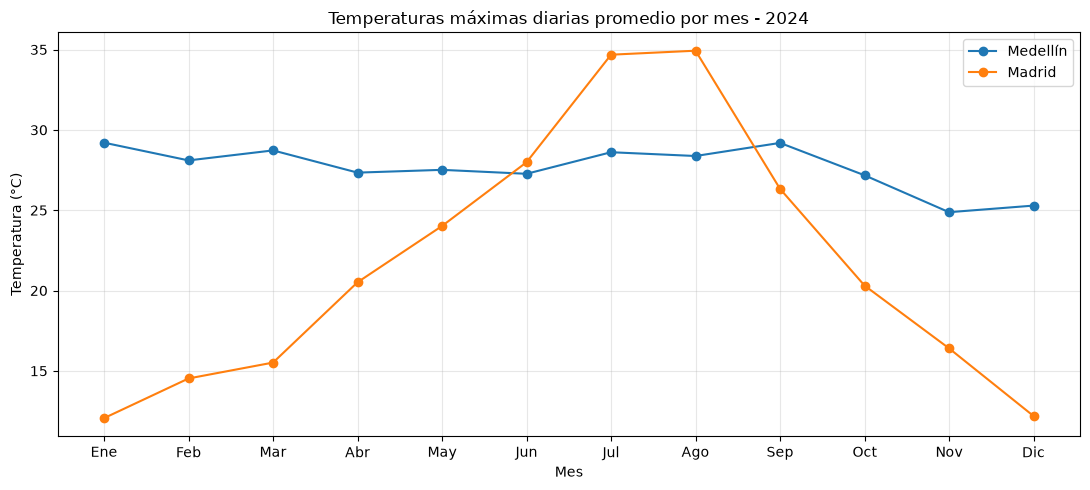

In [12]:
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
         "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

plt.figure(figsize=(11, 5))

plt.plot(
    meses,
    comparacion_temperaturas["Medellín"],
    marker="o",
    label="Medellín"
)

plt.plot(
    meses,
    comparacion_temperaturas["Madrid"],
    marker="o",
    label="Madrid"
)

plt.title("Temperaturas máximas diarias promedio por mes - 2024")
plt.xlabel("Mes")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [13]:
precipitacion_mensual_medellin = (
    medellin.groupby(medellin["time"].dt.month)["precipitation_sum (mm)"]
    .sum()
)

precipitacion_mensual_madrid = (
    madrid.groupby(madrid["time"].dt.month)["precipitation_sum (mm)"]
    .sum()
)

comparacion_precipitaciones = pd.DataFrame({
    "Medellín": precipitacion_mensual_medellin,
    "Madrid": precipitacion_mensual_madrid
})

comparacion_precipitaciones.index.name = "Mes"

display(comparacion_precipitaciones.round(2))

,Medellín,Madrid
Mes,,
1,26.2,61.5
2,102.3,36.9
3,106.4,109.5
4,399.3,8.7
5,326.5,18.0
6,287.9,44.6
7,117.6,4.6
8,162.6,7.9
9,118.9,16.5


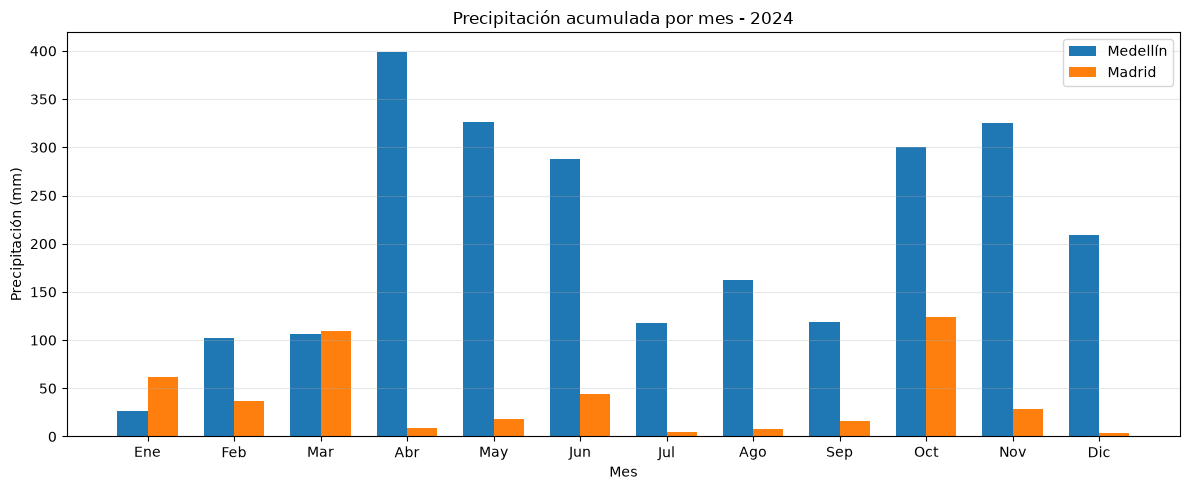

In [14]:
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
         "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

posiciones = np.arange(12)
ancho = 0.35

plt.figure(figsize=(12, 5))

plt.bar(
    posiciones - ancho / 2,
    comparacion_precipitaciones["Medellín"],
    width=ancho,
    label="Medellín"
)

plt.bar(
    posiciones + ancho / 2,
    comparacion_precipitaciones["Madrid"],
    width=ancho,
    label="Madrid"
)

plt.xticks(posiciones, meses)
plt.title("Precipitación acumulada por mes - 2024")
plt.xlabel("Mes")
plt.ylabel("Precipitación (mm)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

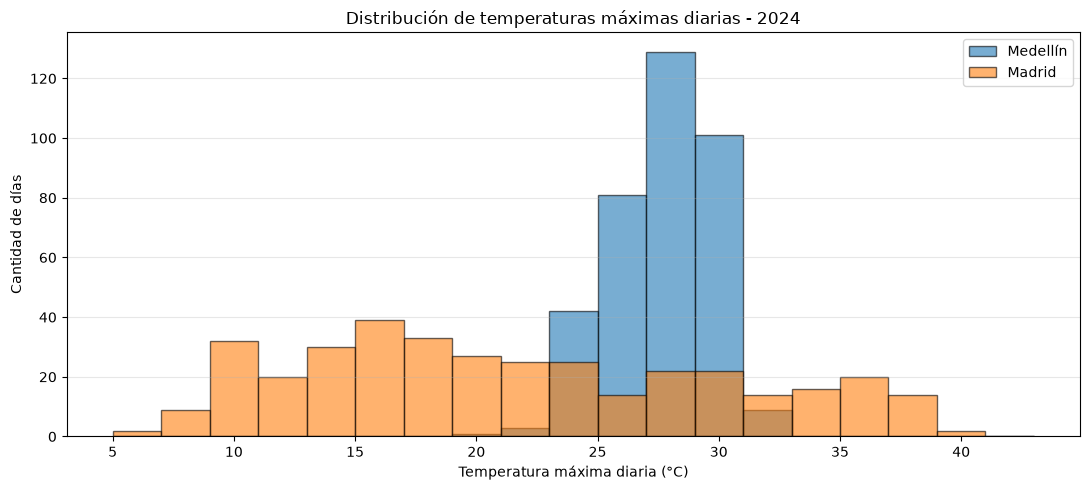

In [15]:
intervalos = np.arange(5, 45, 2)

plt.figure(figsize=(11, 5))

plt.hist(
    temperatura_medellin,
    bins=intervalos,
    alpha=0.6,
    label="Medellín",
    edgecolor="black"
)

plt.hist(
    temperatura_madrid,
    bins=intervalos,
    alpha=0.6,
    label="Madrid",
    edgecolor="black"
)

plt.title("Distribución de temperaturas máximas diarias - 2024")
plt.xlabel("Temperatura máxima diaria (°C)")
plt.ylabel("Cantidad de días")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

### Análisis de los resultados

Al comparar los datos climáticos de Medellín y Madrid durante 2024, encontré diferencias importantes en las temperaturas y las precipitaciones de ambas ciudades.

En Medellín, la temperatura máxima diaria promedio fue de **27,64 °C**, mientras que en Madrid fue de **21,65 °C**. Sin embargo, Madrid alcanzó la temperatura máxima más alta del año, con **39,80 °C**, frente a los **32,20 °C** de Medellín.

La gráfica de temperaturas mensuales muestra que Medellín mantuvo valores relativamente estables durante el año. Por el contrario, Madrid presentó cambios más marcados, con temperaturas más bajas al comienzo y al final del año, y valores más altos durante los meses de verano.

En cuanto a la precipitación, Medellín acumuló **2.482,30 mm**, mientras que Madrid registró **464,10 mm**. Además, Medellín tuvo 342 días con precipitación, frente a 128 en Madrid. Aunque Medellín presentó mayores acumulados en la mayoría de los meses, Madrid registró más lluvia en enero y marzo.

Los histogramas también muestran una diferencia: las temperaturas máximas diarias de Medellín se concentran en un rango más reducido, mientras que las de Madrid se distribuyen en un intervalo más amplio.

Como similitud, ambas ciudades registraron días con temperaturas máximas superiores a 25 °C y presentaron precipitaciones durante el periodo analizado. Sin embargo, la frecuencia y distribución de estos valores fueron diferentes.

Estos resultados corresponden únicamente a 2024 y se basan en datos del modelo de reanálisis ERA5, por lo que no deben interpretarse como mediciones directas de estaciones meteorológicas ni como una descripción definitiva del clima de ambas ciudades.